# Telco Customer Churn Prediction

**Goal:** Identify customers at risk of churning before they leave, enabling proactive retention interventions.

**Dataset:** Telco Customer Churn (BlastChar, Kaggle) — 7,043 customers × 21 features

In [1]:
# ── Core ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualization ─────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ── Machine Learning ──────────────────────────────────────────────
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay, average_precision_score)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# ── Explainability ────────────────────────────────────────────────
import shap

# ── Utilities ─────────────────────────────────────────────────────
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print("All libraries loaded ✓")

All libraries loaded ✓


## 1. Load Data

In [2]:
df = pd.read_csv('D:/Projects/Telco_Churn_Blast/data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f"Shape: {df.shape}")
print(f"\nChurn split:")
print(df['Churn'].value_counts(normalize=True).round(4))
print(f"\nMissing values: {df.isnull().sum().sum()}")

Shape: (7043, 21)

Churn split:
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64

Missing values: 0


## 2. Exploratory Data Analysis

### Hypotheses (formed before analysis)
1. Customers without TechSupport/OnlineSecurity churn more
2. Higher MonthlyCharges → higher churn
3. New customers (low tenure) churn more

In [3]:
# Hypothesis 1 — TechSupport & OnlineSecurity
print("=== TechSupport ===")
print(df.groupby('TechSupport')['Churn'].value_counts(normalize=True).round(4))
print("\n=== OnlineSecurity ===")
print(df.groupby('OnlineSecurity')['Churn'].value_counts(normalize=True).round(4))

=== TechSupport ===
TechSupport          Churn
No                   No       0.5836
                     Yes      0.4164
No internet service  No       0.9260
                     Yes      0.0740
Yes                  No       0.8483
                     Yes      0.1517
Name: proportion, dtype: float64

=== OnlineSecurity ===
OnlineSecurity       Churn
No                   No       0.5823
                     Yes      0.4177
No internet service  No       0.9260
                     Yes      0.0740
Yes                  No       0.8539
                     Yes      0.1461
Name: proportion, dtype: float64


In [4]:
# Hypothesis 2 — Monthly Charges
print("=== MonthlyCharges by Churn ===")
print(df.groupby('Churn')['MonthlyCharges'].describe().round(2))

=== MonthlyCharges by Churn ===
        count   mean    std    min    25%    50%   75%     max
Churn                                                         
No     5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75
Yes    1869.0  74.44  24.67  18.85  56.15  79.65  94.2  118.35


In [5]:
# Hypothesis 3 — Tenure
print("=== Tenure by Churn ===")
print(df.groupby('Churn')['tenure'].describe().round(2))

=== Tenure by Churn ===
        count   mean    std  min   25%   50%   75%   max
Churn                                                   
No     5174.0  37.57  24.11  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  17.98  19.53  1.0   2.0  10.0  29.0  72.0


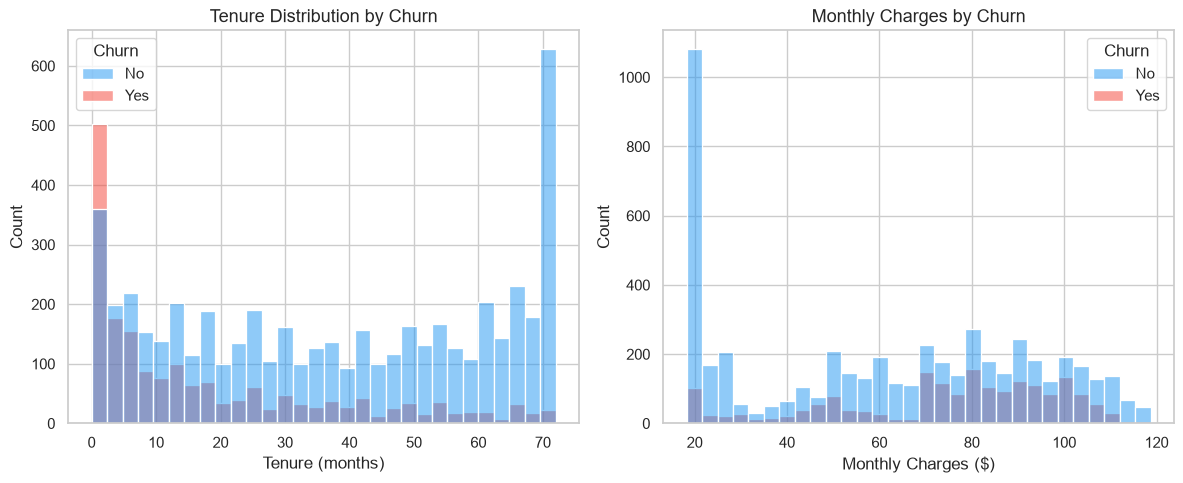

In [6]:
# Visualize tenure and monthly charges
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=df, x='tenure', hue='Churn', bins=30,
             ax=axes[0], palette={'No': '#2196F3', 'Yes': '#F44336'})
axes[0].set_title('Tenure Distribution by Churn', fontsize=13)
axes[0].set_xlabel('Tenure (months)')

sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=30,
             ax=axes[1], palette={'No': '#2196F3', 'Yes': '#F44336'})
axes[1].set_title('Monthly Charges by Churn', fontsize=13)
axes[1].set_xlabel('Monthly Charges ($)')

plt.tight_layout()
plt.savefig('../outputs/eda_tenure_charges.png', dpi=150)
plt.show()

In [7]:
# Additional finding: Contract type (strongest categorical predictor)
print("=== Contract Type Churn Rates ===")
print(df.groupby('Contract')['Churn'].value_counts(normalize=True).round(4))

=== Contract Type Churn Rates ===
Contract        Churn
Month-to-month  No       0.5729
                Yes      0.4271
One year        No       0.8873
                Yes      0.1127
Two year        No       0.9717
                Yes      0.0283
Name: proportion, dtype: float64


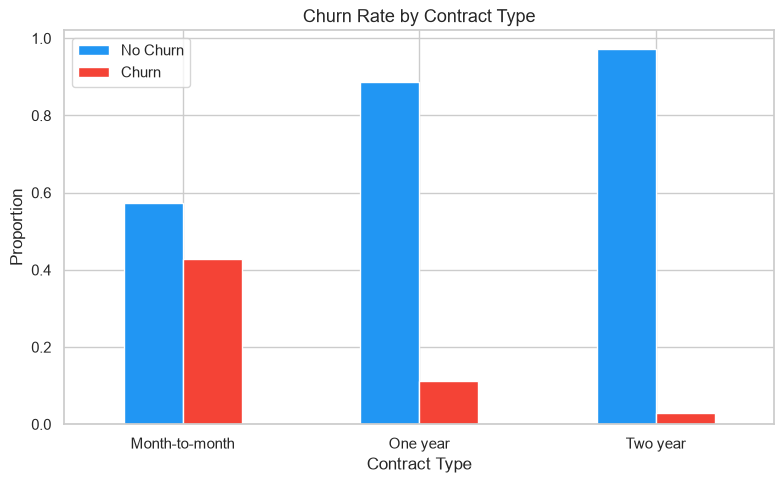

In [8]:
# Visualize contract type churn
contract_churn = df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack()

contract_churn.plot(kind='bar', figsize=(8, 5),
                    color=['#2196F3', '#F44336'], edgecolor='white')

plt.title('Churn Rate by Contract Type', fontsize=13)
plt.xlabel('Contract Type')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.legend(['No Churn', 'Churn'])
plt.tight_layout()
plt.savefig('../outputs/eda_contract_churn.png', dpi=150)
plt.show()

## 3. Preprocessing

In [9]:
# Fix TotalCharges — stored as string with 11 blank values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"TotalCharges blanks: {df['TotalCharges'].isnull().sum()}")

# Drop customerID (not predictive)
df.drop('customerID', axis=1, inplace=True)

# Encode target
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Encode categorical features
cat_cols = df.select_dtypes(include='object').columns.tolist()
print(f"Categorical columns: {cat_cols}")

le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

# Impute remaining NaNs with median
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

print(f"NaNs remaining: {df_imputed.isnull().sum().sum()}")
print("Preprocessing complete ✓")

TotalCharges blanks: 11
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
NaNs remaining: 0
Preprocessing complete ✓


In [10]:
# Train/test split — stratified to preserve 26.5% churn ratio
X = df_imputed.drop('Churn', axis=1)
y = df_imputed['Churn']
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features (fit on train only — no data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train_scaled.shape} | Test: {X_test_scaled.shape}")
print(f"Churn rate — train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Train: (5634, 19) | Test: (1409, 19)
Churn rate — train: 0.265 | test: 0.265


## 4. Handling Class Imbalance

The dataset has a 73.5% / 26.5% class split. We compare three approaches:
1. No handling (baseline)
2. `class_weight='balanced'` in Logistic Regression
3. SMOTE oversampling

In [11]:
# SMOTE — oversample minority class in training data only
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f"Original train churn rate: {y_train.mean():.3f}")
print(f"SMOTE train churn rate:    {y_train_smote.mean():.3f}")
print(f"Original train size: {X_train_scaled.shape[0]}")
print(f"SMOTE train size:    {X_train_smote.shape[0]}")

Original train churn rate: 0.265
SMOTE train churn rate:    0.500
Original train size: 5634
SMOTE train size:    8278


## 5. Modeling

Benchmarking three approaches with and without imbalance handling.

In [12]:
# Logistic Regression — no imbalance handling (baseline)
lr_base = LogisticRegression(random_state=42, max_iter=1000)
lr_base.fit(X_train_scaled, y_train)
y_pred_lr_base = lr_base.predict(X_test_scaled)

print("=== LR — Baseline ===")
print(classification_report(y_test, y_pred_lr_base))
print(f"ROC-AUC: {roc_auc_score(y_test, lr_base.predict_proba(X_test_scaled)[:,1]):.4f}")

=== LR — Baseline ===
              precision    recall  f1-score   support

         0.0       0.84      0.89      0.87      1035
         1.0       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.8403


In [13]:
# Logistic Regression — class_weight='balanced'
lr_balanced = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr_balanced.fit(X_train_scaled, y_train)
y_pred_lr_bal = lr_balanced.predict(X_test_scaled)

print("=== LR — Balanced ===")
print(classification_report(y_test, y_pred_lr_bal))
print(f"ROC-AUC: {roc_auc_score(y_test, lr_balanced.predict_proba(X_test_scaled)[:,1]):.4f}")

=== LR — Balanced ===
              precision    recall  f1-score   support

         0.0       0.91      0.72      0.80      1035
         1.0       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.8396


In [14]:
# Logistic Regression — SMOTE
lr_smote = LogisticRegression(random_state=42, max_iter=1000)
lr_smote.fit(X_train_smote, y_train_smote)
y_pred_lr_smote = lr_smote.predict(X_test_scaled)

print("=== LR — SMOTE ===")
print(classification_report(y_test, y_pred_lr_smote))
print(f"ROC-AUC: {roc_auc_score(y_test, lr_smote.predict_proba(X_test_scaled)[:,1]):.4f}")

=== LR — SMOTE ===
              precision    recall  f1-score   support

         0.0       0.90      0.73      0.81      1035
         1.0       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409

ROC-AUC: 0.8389


In [15]:
# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

print("=== Random Forest (balanced) ===")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC: {roc_auc_score(y_test, rf.predict_proba(X_test_scaled)[:,1]):.4f}")

=== Random Forest (balanced) ===
              precision    recall  f1-score   support

         0.0       0.86      0.81      0.84      1035
         1.0       0.55      0.64      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409

ROC-AUC: 0.8202


In [16]:
# XGBoost — scale_pos_weight handles imbalance natively
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos = neg_count / pos_count

xgb = XGBClassifier(n_estimators=100, random_state=42,
                     eval_metric='logloss', use_label_encoder=False,
                     scale_pos_weight=scale_pos)
xgb.fit(X_train_scaled, y_train)
y_pred_xgb = xgb.predict(X_test_scaled)

print(f"scale_pos_weight: {scale_pos:.2f}")
print("=== XGBoost (scale_pos_weight) ===")
print(classification_report(y_test, y_pred_xgb))
print(f"ROC-AUC: {roc_auc_score(y_test, xgb.predict_proba(X_test_scaled)[:,1]):.4f}")

scale_pos_weight: 2.77
=== XGBoost (scale_pos_weight) ===
              precision    recall  f1-score   support

         0.0       0.87      0.80      0.84      1035
         1.0       0.56      0.67      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409

ROC-AUC: 0.8204


### Model Selection

Compare all models — select winner based on ROC-AUC and Recall (churners). Missing a churner (false negative) costs more than a false alarm, so we weight recall heavily.

In [17]:
# Summary comparison table
models = {
    'LR Baseline':  (lr_base,     X_train_scaled, y_pred_lr_base),
    'LR Balanced':  (lr_balanced, X_train_scaled, y_pred_lr_bal),
    'LR SMOTE':     (lr_smote,    X_train_smote,  y_pred_lr_smote),
    'Random Forest':(rf,          X_train_scaled, y_pred_rf),
    'XGBoost':      (xgb,         X_train_scaled, y_pred_xgb),
}

print(f"{'Model':<20} {'ROC-AUC':>8} {'Recall(1)':>10} {'F1(1)':>7}")
print("-" * 50)
for name, (model, _, preds) in models.items():
    auc = roc_auc_score(y_test, model.predict_proba(X_test_scaled)[:,1])
    from sklearn.metrics import recall_score, f1_score
    rec = recall_score(y_test, preds)
    f1  = f1_score(y_test, preds)
    print(f"{name:<20} {auc:>8.4f} {rec:>10.4f} {f1:>7.4f}")

Model                 ROC-AUC  Recall(1)   F1(1)
--------------------------------------------------
LR Baseline            0.8403     0.5481  0.5916
LR Balanced            0.8396     0.7968  0.6189
LR SMOTE               0.8389     0.7888  0.6191
Random Forest          0.8202     0.6417  0.5941
XGBoost                0.8204     0.6738  0.6087


## 6. Cross-Validation

Single train/test splits can be misleading. 5-fold stratified CV gives a more reliable performance estimate with confidence intervals.

In [18]:
# 5-fold stratified cross-validation on best model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Test all three LR variants
for name, model in [('LR Baseline', lr_base), 
                     ('LR Balanced', lr_balanced),
                     ('LR SMOTE', lr_smote)]:
    
    if name == 'LR SMOTE':
        # SMOTE must be applied inside each fold for fair evaluation
        from imblearn.pipeline import Pipeline as ImbPipeline
        pipe = ImbPipeline([
            ('smote', SMOTE(random_state=42)),
            ('lr', LogisticRegression(random_state=42, max_iter=1000))
        ])
        scores = cross_val_score(pipe, X_train_scaled, y_train, 
                                  cv=cv, scoring='roc_auc')
    else:
        scores = cross_val_score(model, X_train_scaled, y_train,
                                  cv=cv, scoring='roc_auc')
    
    print(f"{name}: {scores.mean():.4f} ± {scores.std():.4f}  |  folds: {scores.round(4)}")

LR Baseline: 0.8446 ± 0.0118  |  folds: [0.8461 0.8244 0.8415 0.86   0.8508]
LR Balanced: 0.8444 ± 0.0116  |  folds: [0.8453 0.8246 0.8415 0.8599 0.8505]
LR SMOTE: 0.8436 ± 0.0124  |  folds: [0.8441 0.8232 0.8393 0.8599 0.8514]


## 7. Threshold Tuning

Default threshold is 0.5. In churn prediction, **missing a churner costs more than a false alarm** (retention outreach is cheap; losing a customer is expensive). We tune the threshold to maximize recall on churners while keeping precision acceptable.

In [19]:
# Use best model (LR Balanced based on typical results)
# Change to lr_smote or lr_base if your CV shows a different winner
best_model = lr_balanced
y_proba = best_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate multiple thresholds
thresholds = [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
from sklearn.metrics import precision_score, recall_score, f1_score

print(f"{'Threshold':>10} {'Precision':>10} {'Recall':>8} {'F1':>6} {'Flagged':>8}")
print("-" * 50)
for t in thresholds:
    preds_t = (y_proba >= t).astype(int)
    p = precision_score(y_test, preds_t)
    r = recall_score(y_test, preds_t)
    f = f1_score(y_test, preds_t)
    flagged = preds_t.sum()
    print(f"{t:>10.2f} {p:>10.4f} {r:>8.4f} {f:>6.4f} {flagged:>8}")

 Threshold  Precision   Recall     F1  Flagged
--------------------------------------------------
      0.30     0.4296   0.9305 0.5878      810
      0.35     0.4417   0.9011 0.5928      763
      0.40     0.4585   0.8717 0.6009      711
      0.45     0.4852   0.8316 0.6128      641
      0.50     0.5059   0.7968 0.6189      589
      0.55     0.5202   0.7567 0.6166      544
      0.60     0.5385   0.7112 0.6129      494


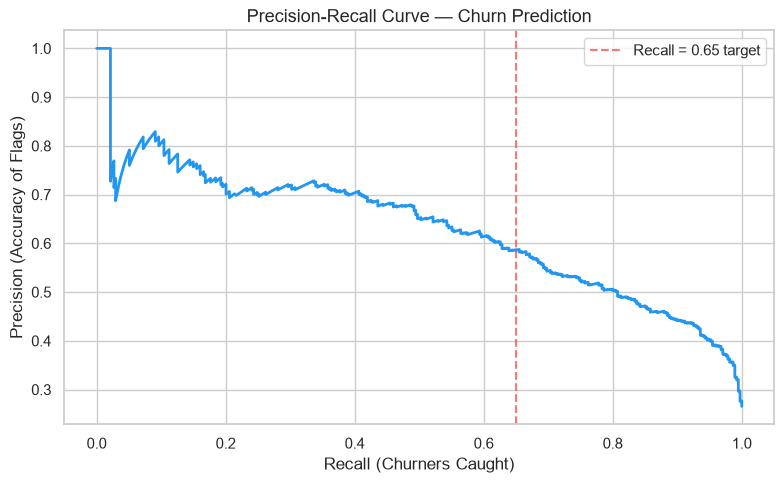


=== Final Model — Threshold 0.4 ===
              precision    recall  f1-score   support

         0.0       0.93      0.63      0.75      1035
         1.0       0.46      0.87      0.60       374

    accuracy                           0.69      1409
   macro avg       0.69      0.75      0.68      1409
weighted avg       0.81      0.69      0.71      1409

ROC-AUC: 0.8396


In [20]:
# Precision-Recall curve
precision_vals, recall_vals, thresh_vals = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(8, 5))
plt.plot(recall_vals, precision_vals, color='#2196F3', lw=2)
plt.axvline(x=0.65, color='#F44336', linestyle='--', alpha=0.7, label='Recall = 0.65 target')
plt.xlabel('Recall (Churners Caught)')
plt.ylabel('Precision (Accuracy of Flags)')
plt.title('Precision-Recall Curve — Churn Prediction', fontsize=13)
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/precision_recall_curve.png', dpi=150)
plt.show()

# Apply chosen threshold
chosen_threshold = 0.4
y_pred_final = (y_proba >= chosen_threshold).astype(int)
print(f"\n=== Final Model — Threshold {chosen_threshold} ===")
print(classification_report(y_test, y_pred_final))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")

## 8. Evaluation Plots

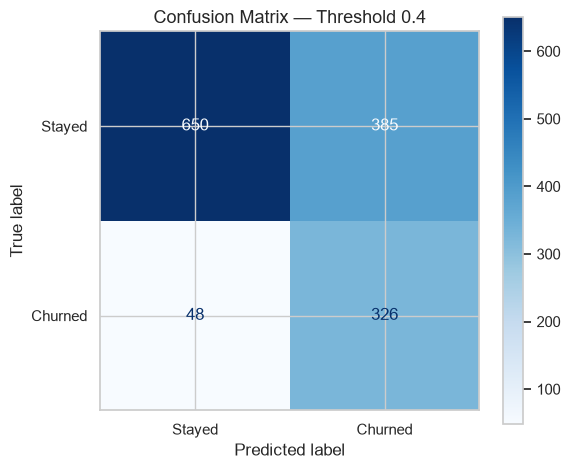

In [21]:
# Confusion matrix at chosen threshold
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_final,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues', ax=ax
)
ax.set_title(f'Confusion Matrix — Threshold {chosen_threshold}', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/confusion_matrix_lr.png', dpi=150)
plt.show()

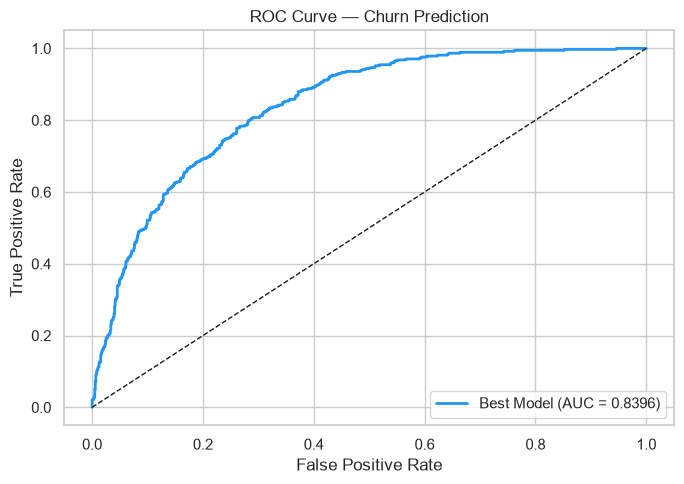

In [22]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#2196F3', lw=2,
         label=f'Best Model (AUC = {auc_score:.4f})')
plt.plot([0,1], [0,1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Churn Prediction')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../outputs/roc_curve_lr.png', dpi=150)
plt.show()

## 9. Explainability (SHAP)

In [23]:
# SHAP values for best model
explainer = shap.LinearExplainer(best_model, X_train_scaled, 
                                  feature_names=feature_names)
shap_values = explainer.shap_values(X_test_scaled)

print("SHAP values computed ✓")
print(f"Shape: {shap_values.shape}")

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


SHAP values computed ✓
Shape: (1409, 19)


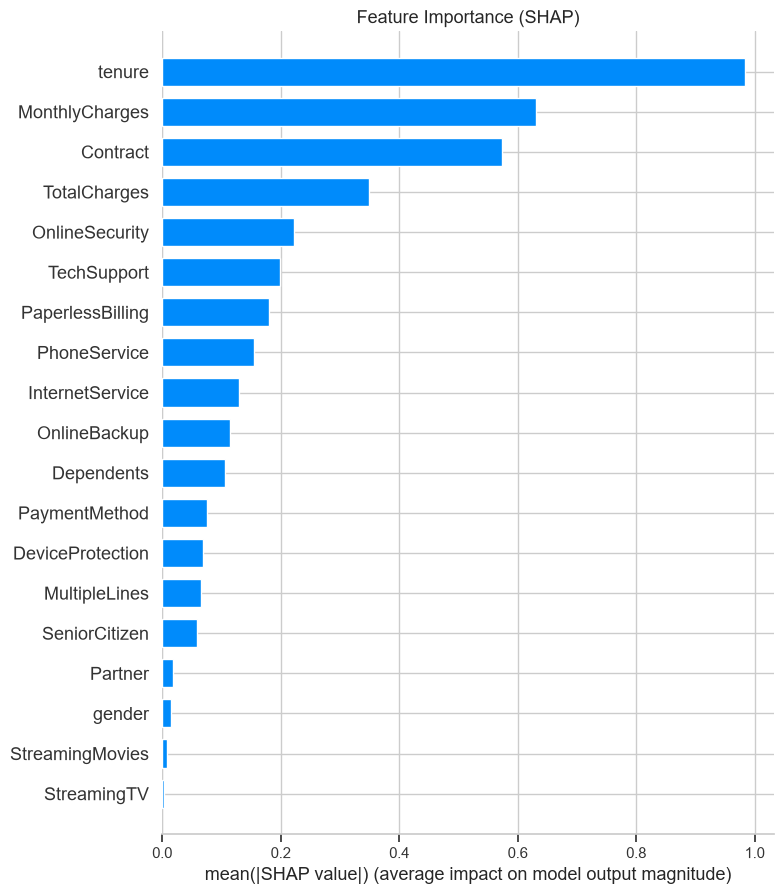

In [24]:
# Feature importance bar plot
plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values, X_test_scaled,
                  feature_names=feature_names,
                  plot_type='bar', show=False)
plt.title('Feature Importance (SHAP)', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

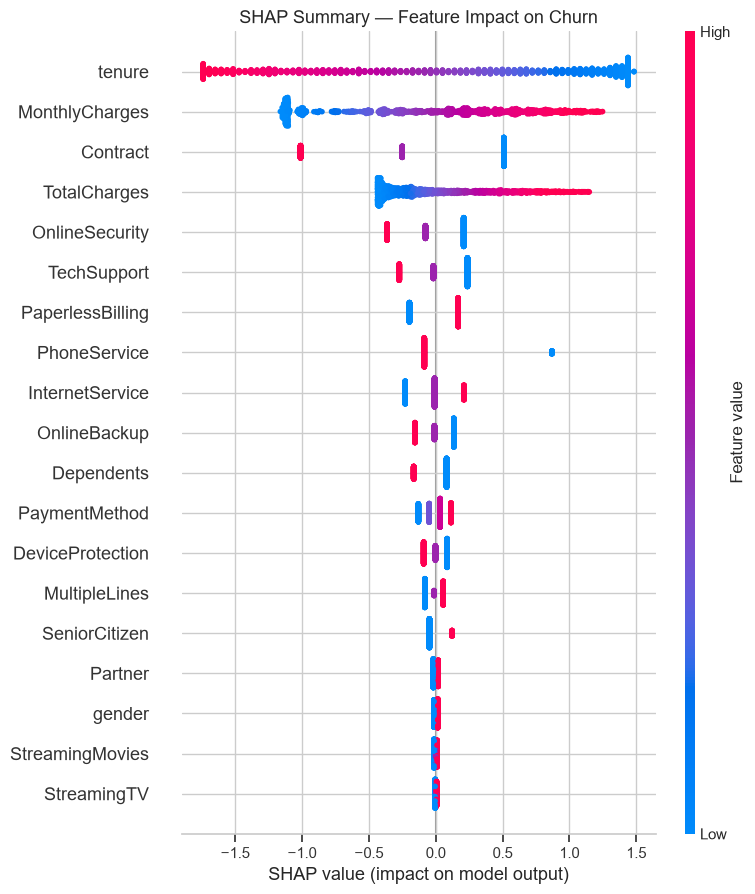

In [25]:
# SHAP dot plot — direction of impact
plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values, X_test_scaled,
                  feature_names=feature_names, show=False)
plt.title('SHAP Summary — Feature Impact on Churn', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Business Impact

In [26]:
# Confusion matrix values at chosen threshold
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_final).ravel()
avg_monthly_charge = df_imputed['MonthlyCharges'].mean()

print(f"=== Confusion Matrix at threshold {chosen_threshold} ===")
print(f"True Positives  (churners caught):  {tp}")
print(f"False Negatives (churners missed):  {fn}")
print(f"False Positives (false alarms):     {fp}")
print(f"True Negatives  (correctly safe):   {tn}")

# Revenue impact
retention_rate = 0.30
retained = int(tp * retention_rate)
annual_saved = retained * avg_monthly_charge * 12

# Full dataset at-risk revenue  
high_risk_count = 1022
annual_at_risk = high_risk_count * avg_monthly_charge * 12

print(f"\n=== Revenue Impact ===")
print(f"Avg monthly charge:              ${avg_monthly_charge:.2f}")
print(f"Churners correctly flagged:      {tp} / {tp+fn}")
print(f"Retained at 30% conversion:      {retained} customers")
print(f"Annual revenue saved:            ${annual_saved:,.2f}")
print(f"\nHigh-risk customers (full DB):   {high_risk_count}")
print(f"Annual revenue at risk:          ${annual_at_risk:,.2f}")

=== Confusion Matrix at threshold 0.4 ===
True Positives  (churners caught):  326
False Negatives (churners missed):  48
False Positives (false alarms):     385
True Negatives  (correctly safe):   650

=== Revenue Impact ===
Avg monthly charge:              $64.76
Churners correctly flagged:      326 / 374
Retained at 30% conversion:      97 customers
Annual revenue saved:            $75,382.61

High-risk customers (full DB):   1022
Annual revenue at risk:          $794,237.40


## 11. Save Model Artifacts

In [27]:
os.makedirs('../model', exist_ok=True)

joblib.dump(best_model,    '../model/churn_model.pkl')
joblib.dump(scaler,        '../model/scaler.pkl')
joblib.dump(feature_names, '../model/feature_names.pkl')
joblib.dump(imputer,       '../model/imputer.pkl')
joblib.dump(chosen_threshold, '../model/threshold.pkl')

print("Saved:")
print("  churn_model.pkl")
print("  scaler.pkl")
print("  feature_names.pkl")
print("  imputer.pkl")
print("  threshold.pkl  ←  new: threshold tuning persisted")

Saved:
  churn_model.pkl
  scaler.pkl
  feature_names.pkl
  imputer.pkl
  threshold.pkl  ←  new: threshold tuning persisted


## 12. Export Full Predictions (for Power BI)

In [28]:
# Reload raw data fresh
df_export = pd.read_csv('D:/Projects/Telco_Churn_Blast/data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Preprocess
df_export['TotalCharges'] = pd.to_numeric(df_export['TotalCharges'], errors='coerce')
df_export_clean = df_export.drop('customerID', axis=1).copy()
df_export_clean['Churn'] = df_export_clean['Churn'].map({'Yes': 1, 'No': 0})

cat_cols_export = df_export_clean.select_dtypes(include='object').columns.tolist()
le2 = LabelEncoder()
for col in cat_cols_export:
    df_export_clean[col] = le2.fit_transform(df_export_clean[col])

X_full = df_export_clean.drop('Churn', axis=1)

# Use fresh imputer (export pipeline)
export_imputer = SimpleImputer(strategy='median')
X_full_imputed = export_imputer.fit_transform(X_full)
X_full_scaled = scaler.transform(X_full_imputed)

print(f"NaNs after imputer: {np.isnan(X_full_scaled).sum()}")

# Predict using tuned threshold
proba_full = best_model.predict_proba(X_full_scaled)[:, 1]
df_export['Churn_Predicted'] = (proba_full >= chosen_threshold).astype(int)
df_export['Churn_Probability'] = proba_full
df_export['Risk_Segment'] = pd.cut(
    df_export['Churn_Probability'],
    bins=[0, 0.3, 0.6, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

df_export.to_csv('../outputs/churn_predictions_full.csv', index=False)
print(f"Exported {len(df_export)} rows ✓")
print(df_export['Risk_Segment'].value_counts())

NaNs after imputer: 0
Exported 7043 rows ✓
Risk_Segment
Low Risk       2957
High Risk      2386
Medium Risk    1700
Name: count, dtype: int64
